# Lab 4 — Build the Audience, Then Buy It
Name: Nazar Harbarchuk | Group: KM-41

## Setup

In [1]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab4-tv-audiences/versions/2")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")
survey = pd.read_csv(f"{DATA}/purchase_survey.txt", sep="\t", dtype=str, keep_default_na=False)
survey_layout = pd.read_csv(f"{DATA}/purchase_survey_layout.txt", sep="\t", dtype=str)
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")
universe = pd.read_parquet(f"{DATA}/universe.parquet")

Using Colab cache for faster access to the 'adtech-lab4-tv-audiences' dataset.


In [2]:
# Lab rules applied once here, so every task below uses the same definitions.
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

def show(df, formats=None):
    """Print a table with the lab's number formats (formats: column -> format spec)."""
    out = df.copy()
    for column, spec in (formats or {}).items():
        out[column] = out[column].map(lambda x, s=spec: format(x, s) if pd.notna(x) else "-")
    print(out.to_string(index=False))

def label(program_name, network_code):
    """Program (NETWORK), as the lab asks."""
    return f"{program_name} ({network_code})"

# Panel: October 1-31 2024, people are the R and L records (no H, no guests).
OCTOBER = [f"2024-10-{d:02d}" for d in range(1, 32)]
daily_weights["broadcast_date"] = daily_weights["broadcast_date"].astype(str)
programs["broadcast_date"] = programs["broadcast_date"].astype(str)
person_days = daily_weights[daily_weights["resp_type"].isin(["R", "L"]) &
                            daily_weights["broadcast_date"].isin(OCTOBER)]

# Person attributes from viewer_attributes: type (101 member, 102 long-term visitor), sex, age.
person_ids = set(viewer_attributes.loc[viewer_attributes["attr_id"].isin([101, 102]), "respondent_id"])
person_age = viewer_attributes[viewer_attributes["attr_id"] == 300].set_index("respondent_id")["value"]
person_sex = (viewer_attributes[viewer_attributes["attr_id"].isin([201, 202])]
              .set_index("respondent_id")["attr_id"].map({201: "Men", 202: "Women"}))

# Adult panel members: R and L people in viewer_attributes aged 18+.
ADULTS = sorted(pid for pid in person_ids if person_age.get(pid, -1) >= 18)
P2_PLUS = sorted(person_ids)

def audience_size(members):
    """Each broadcast day: sum of daily weights of in-tab members. Size = mean of the 31 daily sums."""
    return daily_audience(members).mean()

def daily_audience(members):
    """Daily sums of in-tab members' weights, one value per October broadcast day."""
    days = person_days[person_days["respondent_id"].isin(set(members))]
    return days.groupby("broadcast_date")["weight"].sum().reindex(OCTOBER, fill_value=0)

## Task 1.0 — Clean the survey file

In [3]:
LAYOUT_CODES = survey_layout.loc[survey_layout["RECTYPE"] == "B", ["KEYWORD", "Text", "SAMPLE"]]
VALID_CODES = set(LAYOUT_CODES["KEYWORD"])
PAIR_CODES = {"X710101": 1, "X710102": 2, "X710103": 3}
ANY_CODE = "X710100"
BRAND_CODES = {"X710201": "STRIDE", "X710202": "KESTREL", "X710203": "EASYWALK"}
YES_VALUES = {"1", "1.0", "y", "yes", "true"}
NO_VALUES = {"0", "0.0", "n", "no"}

raw = survey.copy()
adult_set = set(ADULTS)

# 1. Lines that are not data: the header repeated inside the file and a "TOTAL ROWS" trailer.
is_header = raw["RESPID"].str.strip().eq("RESPID")
is_trailer = raw["RESPID"].str.strip().str.startswith("TOTAL ROWS")
data = raw[~is_header & ~is_trailer].copy()

# 2. Normalise the text fields, keeping track of what had to be repaired.
respid_strip = data["RESPID"].str.strip()
had_space_id = data["RESPID"] != respid_strip
had_float_id = respid_strip.str.endswith(".0")
data["respondent_id"] = pd.to_numeric(respid_strip.str.replace(r"\.0$", "", regex=True), errors="coerce")

keyword_clean = data["KEYWORD"].str.strip().str.upper()
had_space_kw = data["KEYWORD"] != data["KEYWORD"].str.strip()
had_lower_kw = data["KEYWORD"].str.strip() != keyword_clean
data["keyword"] = keyword_clean

value_clean = data["VALUE"].str.strip().str.lower()
is_yes = value_clean.isin(YES_VALUES)
is_no = value_clean.isin(NO_VALUES)
is_blank = value_clean.eq("")
odd_yes = is_yes & (data["VALUE"] != "1")

# 3. Codes and people the vendor promised but did not deliver.
not_in_layout = ~data["keyword"].isin(VALID_CODES)
known_ids = set(viewer_attributes["respondent_id"])
not_adult = ~data["respondent_id"].isin(adult_set)
child_id = not_adult & data["respondent_id"].isin(person_ids)
guest_id = not_adult & ~data["respondent_id"].isin(known_ids) & (data["respondent_id"] % 100 >= 81)
unknown_id = not_adult & ~child_id & ~guest_id

# 4. Keep yes answers with a layout code from adult panel members, once per person and keyword.
valid = data[is_yes & ~not_in_layout & ~not_adult]
duplicated = valid.duplicated(["respondent_id", "keyword"])
clean = valid[~duplicated][["respondent_id", "keyword"]]

# 5. Two pair counts: keep the higher one.
pair_rows = clean[clean["keyword"].isin(PAIR_CODES)].assign(pairs=lambda d: d["keyword"].map(PAIR_CODES))
pair_counts_per_person = pair_rows.groupby("respondent_id").size()
two_pair_people = int((pair_counts_per_person > 1).sum())
top_pair = pair_rows.sort_values("pairs").drop_duplicates("respondent_id", keep="last")
lower_pair_rows = pair_rows.index.difference(top_pair.index)
clean = clean.drop(index=lower_pair_rows)

# 6. One row per adult panel member: a pair count or any brand makes a buyer, even without "Any".
people = pd.DataFrame(index=pd.Index(ADULTS, name="respondent_id"))
people["buyer"] = people.index.isin(clean["respondent_id"])
people["pairs"] = top_pair.set_index("respondent_id")["pairs"].reindex(people.index).fillna(0).astype(int)
for code, brand in BRAND_CODES.items():
    people[brand.lower()] = people.index.isin(clean.loc[clean["keyword"] == code, "respondent_id"])
has_any = set(clean.loc[clean["keyword"] == ANY_CODE, "respondent_id"])
buyers_without_any = int((people["buyer"] & ~people.index.isin(has_any)).sum())

print("Survey data rows:", len(data))
print("Clean yes answers:", len(clean))
print("Adult panel members:", len(people))
print("Non-buyers:", int((~people["buyer"]).sum()))
print("People with two pair counts:", two_pair_people)
print()

bad_records = pd.DataFrame([
    ("Header line repeated inside the data", int(is_header.sum()), "dropped"),
    ("'TOTAL ROWS' trailer line", int(is_trailer.sum()), "dropped"),
    ("RESPID with leading/trailing spaces", int(had_space_id.sum()), "fixed: stripped"),
    ("RESPID written as a float ('.0')", int(had_float_id.sum()), "fixed: '.0' removed"),
    ("KEYWORD with trailing spaces", int(had_space_kw.sum()), "fixed: stripped"),
    ("KEYWORD in lower case", int(had_lower_kw.sum()), "fixed: upper-cased"),
    ("VALUE a yes but not '1' (1.0, y, Y, yes, TRUE)", int(odd_yes.sum()), "fixed: read as yes"),
    ("VALUE a no (0, 0.0, N, no) in a yes-only export", int(is_no.sum()), "dropped"),
    ("VALUE blank", int(is_blank.sum()), "dropped (not a confirmed yes)"),
    ("KEYWORD not in the layout (X880112, X880140, X880141, X902001)", int(not_in_layout.sum()), "dropped"),
    ("RESPID of a child (panel member under 18)", int(child_id.sum()), "dropped"),
    ("RESPID of a guest (id ending 81+)", int(guest_id.sum()), "dropped"),
    ("RESPID not in the panel (test ids, unknown people)", int(unknown_id.sum()), "dropped"),
    ("Same yes answer twice for a person and keyword", int(duplicated.sum()), "dropped the repeat"),
    ("Second, lower pair count for a person", len(lower_pair_rows), "dropped (kept the higher)"),
    ("Buyer with a pair count/brand but no 'Any' row", buyers_without_any, "fixed: counted as a buyer"),
], columns=["bad record", "rows", "what I did"])
print("table: kind of bad record, rows, what you did (a row can have more than one problem)")
show(bad_records)
print()

my_counts = {ANY_CODE: int(people["buyer"].sum())}
my_counts.update({code: int((people["pairs"] == n).sum()) for code, n in PAIR_CODES.items()})
my_counts.update({code: int(clean["keyword"].eq(code).sum()) for code in VALID_CODES - set(PAIR_CODES) - {ANY_CODE}})
check = LAYOUT_CODES.assign(my_count=LAYOUT_CODES["KEYWORD"].map(my_counts), SAMPLE=LAYOUT_CODES["SAMPLE"].astype(int))
check["match"] = check["my_count"] == check["SAMPLE"]
print("table: KEYWORD, your count, layout SAMPLE")
show(check[["KEYWORD", "Text", "my_count", "SAMPLE", "match"]])
print()

# The file as delivered: every row taken at face value, exact codes only, no cleaning.
raw_kestrel = int((raw["KEYWORD"] == "X710202").sum())
raw_any_people = raw.loc[raw["KEYWORD"] == ANY_CODE, "RESPID"].nunique()
raw_people_in_file = data["RESPID"].nunique()
clean_share = people["buyer"].mean()
print("Kestrel buyers, raw file / clean:", raw_kestrel, "/", int(people["kestrel"].sum()),
      f"(+{(raw_kestrel / people['kestrel'].sum() - 1) * 100:.1f}%)")
print("Share of buyers, raw 'Any' rows / clean:", f"{raw_any_people / len(people):.3f}", "/", f"{clean_share:.3f}")
print("Share of buyers, every id in the raw file / clean:", f"{raw_people_in_file / len(people):.3f}", "/", f"{clean_share:.3f}")

Survey data rows: 18346
Clean yes answers: 15397
Adult panel members: 8010
Non-buyers: 3231
People with two pair counts: 113

table: kind of bad record, rows, what you did (a row can have more than one problem)
                                                    bad record  rows                    what I did
                          Header line repeated inside the data     2                       dropped
                                     'TOTAL ROWS' trailer line     1                       dropped
                           RESPID with leading/trailing spaces   573               fixed: stripped
                              RESPID written as a float ('.0')   533           fixed: '.0' removed
                                  KEYWORD with trailing spaces   370               fixed: stripped
                                         KEYWORD in lower case   734            fixed: upper-cased
                VALUE a yes but not '1' (1.0, y, Y, yes, TRUE)  1194            fixed: read as y

**Answer:** what was wrong with the file; how far off the raw file would have been.

Answer: The raw survey file had several issues:

Formatting & values: Removed 2 repeated header lines and 1 trailer row; standardized stray spaces, float IDs (533), lowercase keywords (734), and six spellings of "yes" (1, 1.0, y, Y, yes, TRUE); dropped 619 "no" answers and 123 blanks.

Invalid codes & people: Dropped 738 rows with unknown codes (X880112, X880140, X880141, X902001), 273 children, 84 guests, and 66 non-panel/fake IDs.

Duplicates & missing flags: Dropped 933 duplicate answers, kept the higher pair count for 113 people with two entries, and counted 238 respondents with a pair count or brand but no Any row as buyers.

After cleaning, all nine codes match the layout's SAMPLE exactly (4,779 buyers; 1,810 / 1,308 / 1,661 by pairs; 354 Kestrel buyers).

Using the raw file would have skewed the results in opposite directions:

Kestrel buyers: Counting raw X710202 rows gives 516 instead of 354 (+45.8%), inflated by duplicates, "no"s, children, guests, and fake IDs.

Buyer share: Counting raw Any rows gives 0.548 instead of 0.597 (due to missing Any rows and unstandardized formatting), while treating everyone in the file as a buyer gives 0.885.

## Task 1.1 — Four definitions

In [4]:
AUDIENCES = {
    "Adults 18+": ADULTS,
    "Shoe buyers": people.index[people["buyer"]].tolist(),
    "Heavy buyers (3+)": people.index[people["pairs"] == 3].tolist(),
    "Kestrel buyers": people.index[people["kestrel"]].tolist(),
    "Adults 25-54": [pid for pid in ADULTS if 25 <= person_age[pid] <= 54],
}
sizes = {name: audience_size(members) for name, members in AUDIENCES.items()}

print("Adults 18+ (M):", f"{sizes['Adults 18+'] / 1e6:.1f}")
print("Shoe buyers (M):", f"{sizes['Shoe buyers'] / 1e6:.1f}")
print("Heavy buyers, 3+ pairs (M):", f"{sizes['Heavy buyers (3+)'] / 1e6:.1f}")
print("Kestrel buyers (M):", f"{sizes['Kestrel buyers'] / 1e6:.1f}")
print("Adults 25-54 (M):", f"{sizes['Adults 25-54'] / 1e6:.1f}")
print("Kestrel buyers in panel (n):", len(AUDIENCES["Kestrel buyers"]))
print()
size_table = pd.DataFrame({"audience": list(sizes),
                           "panel n": [len(m) for m in AUDIENCES.values()],
                           "size (M)": [v / 1e6 for v in sizes.values()],
                           "share of adults": [v / sizes["Adults 18+"] for v in sizes.values()]})
show(size_table, {"size (M)": ".1f", "share of adults": ".3f"})

Adults 18+ (M): 252.6
Shoe buyers (M): 148.1
Heavy buyers, 3+ pairs (M): 49.6
Kestrel buyers (M): 10.0
Adults 25-54 (M): 123.7
Kestrel buyers in panel (n): 354

         audience  panel n size (M) share of adults
       Adults 18+     8010    252.6           1.000
      Shoe buyers     4779    148.1           0.586
Heavy buyers (3+)     1661     49.6           0.196
   Kestrel buyers      354     10.0           0.040
     Adults 25-54     4814    123.7           0.490


## Task 1.2 — Who are they?

table: share of each audience in six groups
audience    Adults 18+ Shoe buyers Heavy buyers (3+) Kestrel buyers Adults 25-54
group                                                                           
Men 18-34        0.144       0.140             0.111          0.118        0.174
Men 35-54        0.160       0.158             0.138          0.189        0.326
Men 55+          0.185       0.186             0.189          0.126        0.000
Women 18-34      0.144       0.140             0.139          0.181        0.174
Women 35-54      0.160       0.178             0.226          0.265        0.326
Women 55+        0.208       0.197             0.196          0.121        0.000

table: index vs adults 18+
audience    Adults 18+ Shoe buyers Heavy buyers (3+) Kestrel buyers Adults 25-54
group                                                                           
Men 18-34        100.0        97.4              77.1           82.1        121.2
Men 35-54        100.0        99.2   

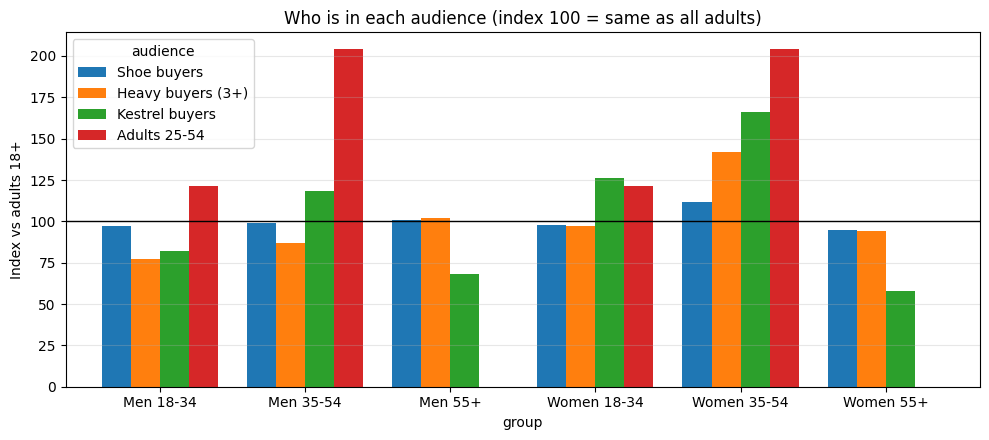

In [5]:
def age_group(age):
    return "18-34" if age < 35 else ("35-54" if age < 55 else "55+")

GROUPS = [f"{sex} {age}" for sex in ["Men", "Women"] for age in ["18-34", "35-54", "55+"]]
adult_group = pd.Series({pid: f"{person_sex[pid]} {age_group(person_age[pid])}" for pid in ADULTS})

profile_rows = []
for name, members in AUDIENCES.items():
    members = set(members)
    total = sizes[name]
    for group in GROUPS:
        in_group = [pid for pid in adult_group.index[adult_group == group] if pid in members]
        profile_rows.append({"audience": name, "group": group, "share": audience_size(in_group) / total})
profile = pd.DataFrame(profile_rows)
adult_shares = profile[profile["audience"] == "Adults 18+"].set_index("group")["share"]
profile["index"] = profile["share"] / profile["group"].map(adult_shares) * 100

share_table = profile.pivot(index="group", columns="audience", values="share").loc[GROUPS, list(AUDIENCES)]
index_table = profile.pivot(index="group", columns="audience", values="index").loc[GROUPS, list(AUDIENCES)]
print("table: share of each audience in six groups")
print(share_table.map(lambda x: f"{x:.3f}").to_string())
print()
print("table: index vs adults 18+")
print(index_table.map(lambda x: f"{x:.1f}").to_string())

fig, ax = plt.subplots(figsize=(10, 4.5))
index_table.drop(columns="Adults 18+").plot(kind="bar", ax=ax, width=0.8)
ax.axhline(100, color="black", linewidth=1)
ax.set_ylabel("Index vs adults 18+")
ax.set_title("Who is in each audience (index 100 = same as all adults)")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Answer:

Target definition for Kestrel: Use heavy buyers (3+ pairs) (49.6M people; 1,661 panelists, ~20% of adults). It directly matches the brief, shows a clear demographic skew (peaking on women 35–54 at index 142, low on men 18–34 at 77, and ~100 for 55+), and is large enough to rate programs reliably. Current Kestrel buyers (10.0M; 354 panelists) are too small for stable program ratings and should only serve as a check or lookalike seed. Adults 25–54 (123.7M) is a poor proxy: it is 2.5x too large, over-indexes on 35–54 (204), and completely misses heavy buyers aged 55+ (38.5% of the target: 0.189 + 0.196).

Why "athletic-shoe buyers" mirrors all adults: Because 58.6% of adults bought at least one pair in the last 12 months, the group includes most of the population and naturally matches its demographic profile (all indices sit between 94.6 and 111.4). Clear differentiation only appears when narrowing to heavy or brand buyers.

Limitation of fused data: Since purchase data was fused using only age, sex, and income, buyers and non-buyers within the same demographic cell have identical viewing patterns by construction. The data cannot show whether actual runners watch more sports or HGTV than other women 35–54—any true link between category interest and viewing is invisible.

## Task 2.1 — Programs by audience

In [6]:
# Person viewing joined to the day's daily weight (people = R and L, no H, no guests).
person_viewings = viewings[viewings["resp_type"].isin(["R", "L"])].copy()
person_viewings["broadcast_date"] = (person_viewings["start_ts"] - pd.Timedelta(hours=6)).dt.strftime("%Y-%m-%d")
day_weight = person_days.set_index(["respondent_id", "broadcast_date"])["weight"]

def telecast_minutes(telecasts):
    """Minutes each person viewed each telecast: viewings on the telecast's network overlapping it.
    (Joined on network and broadcast day first, to keep the candidate pairs small.)"""
    pairs = telecasts[["telecast_id", "network_code", "broadcast_date", "start_ts", "end_ts"]].merge(
        person_viewings[["respondent_id", "network_code", "broadcast_date", "start_ts", "end_ts"]],
        on=["network_code", "broadcast_date"], suffixes=("", "_v"))
    pairs = pairs[(pairs["start_ts_v"] < pairs["end_ts"]) & (pairs["end_ts_v"] > pairs["start_ts"])].copy()
    overlap = pairs["end_ts_v"].clip(upper=pairs["end_ts"]) - pairs["start_ts_v"].clip(lower=pairs["start_ts"])
    pairs["minutes"] = overlap.dt.total_seconds() / 60.0
    pairs["weight"] = day_weight.reindex(pd.MultiIndex.from_arrays(
        [pairs["respondent_id"], pairs["broadcast_date"]])).to_numpy()
    return pairs.dropna(subset=["weight"])[["telecast_id", "respondent_id", "broadcast_date", "minutes", "weight"]]

def ratings_for(telecasts, minutes, members):
    """Average-minute rating per telecast for an audience: sum(weight x minutes) / (minutes x day's size) x 100."""
    members = set(members)
    daily = daily_audience(members)
    viewed = minutes[minutes["respondent_id"].isin(members)]
    weighted_minutes = (viewed["weight"] * viewed["minutes"]).groupby(viewed["telecast_id"]).sum()
    t = telecasts.set_index("telecast_id")
    wm = weighted_minutes.reindex(t.index, fill_value=0.0)
    size = t["broadcast_date"].map(daily)
    return pd.DataFrame({"rating": wm / (t["duration_min"] * size) * 100,
                         "viewers": wm / t["duration_min"],
                         "panelists": viewed.groupby("telecast_id")["respondent_id"].nunique().reindex(t.index, fill_value=0)})

# Rate card: program rows win over time rows; time rows match the broadcast weekday and clock.
def clock_minutes(hhmm):
    h, m = map(int, hhmm.split(":"))
    return h * 60 + m

program_rows = rate_card[rate_card["program_name"].notna()]
time_rows = rate_card[rate_card["program_name"].isna()].explode("weekdays")
time_rows = time_rows.assign(weekday=time_rows["weekdays"].astype(int),
                             start_min=time_rows["start_time"].map(clock_minutes),
                             end_min=time_rows["end_time"].map(clock_minutes))

def price_30s(telecast):
    """Cost of a :30 in the telecast, priced at its start time as in Lab 2."""
    by_program = program_rows[(program_rows["network_code"] == telecast["network_code"]) &
                              (program_rows["program_name"] == telecast["program_name"])]
    if len(by_program):
        return by_program["cost_30s_usd"].iloc[0]
    weekday = pd.Timestamp(telecast["broadcast_date"]).weekday()
    start = telecast["start_ts"]
    clock = start.hour * 60 + start.minute + (24 * 60 if start.hour < 6 else 0)
    by_time = time_rows[(time_rows["network_code"] == telecast["network_code"]) & (time_rows["weekday"] == weekday) &
                        (time_rows["start_min"] <= clock) & (time_rows["end_min"] > clock)]
    return by_time["cost_30s_usd"].iloc[0]

PROGRAMS_8 = [("Sunday Night Football", "NBC", "NFL Football"), ("Monday Night Football", "ABC", "NFL Football"),
              ("Dancing with the Stars", "ABC", "Dancing with the Stars"), ("NCIS", "CBS", "NCIS"),
              ("Hannity", "FNC", "Hannity"), ("Unsellable Houses", "HGTV", "Unsellable Houses"),
              ("Halloween Wars", "FOOD", "Halloween Wars"), ("Grotesquerie", "FX", "Grotesquerie")]

prime = programs[(programs["daypart"] == "Prime") & programs["broadcast_date"].isin(OCTOBER)]
telecasts_8 = pd.concat([prime[(prime["network_code"] == net) & (prime["program_name"] == name)].assign(program=label(show_name, net))
                         for show_name, net, name in PROGRAMS_8])
telecasts_8["cost_30s"] = telecasts_8.apply(price_30s, axis=1)
minutes_8 = telecast_minutes(telecasts_8)

HEAVY = AUDIENCES["Heavy buyers (3+)"]
KESTREL = AUDIENCES["Kestrel buyers"]
per_telecast = telecasts_8.set_index("telecast_id")[["program", "broadcast_date", "cost_30s"]].join(
    ratings_for(telecasts_8, minutes_8, ADULTS).add_prefix("adults_")).join(
    ratings_for(telecasts_8, minutes_8, HEAVY).add_prefix("heavy_")).join(
    ratings_for(telecasts_8, minutes_8, KESTREL).add_prefix("kestrel_"))

program_table = per_telecast.groupby("program", sort=False).agg(
    telecasts=("cost_30s", "size"), adults_rating=("adults_rating", "mean"), target_rating=("heavy_rating", "mean"),
    adults_viewers=("adults_viewers", "mean"), target_viewers=("heavy_viewers", "mean"),
    kestrel_rating=("kestrel_rating", "mean"), cost_30s=("cost_30s", "mean"),
    target_panelists=("heavy_panelists", "mean"), kestrel_panelists=("kestrel_panelists", "mean")).reset_index()
program_table["target_viewers_k"] = program_table["target_viewers"] / 1e3
program_table["composition"] = program_table["target_viewers"] / program_table["adults_viewers"]
program_table["index"] = program_table["target_rating"] / program_table["adults_rating"] * 100
program_table["adults_cpm"] = program_table["cost_30s"] / program_table["adults_viewers"] * 1000
program_table["target_cpm"] = program_table["cost_30s"] / program_table["target_viewers"] * 1000
program_table["kestrel_index"] = program_table["kestrel_rating"] / program_table["adults_rating"] * 100

print("table: 8 programs, October prime time, target = heavy athletic-shoe buyers (3+ pairs)")
show(program_table[["program", "telecasts", "adults_rating", "target_rating", "target_viewers_k", "composition",
                    "index", "cost_30s", "adults_cpm", "target_cpm"]],
     {"adults_rating": ".2f", "target_rating": ".2f", "target_viewers_k": ".0f", "composition": ".3f",
      "index": ".1f", "cost_30s": ".0f", "adults_cpm": ".2f", "target_cpm": ".2f"})
print("Target universe (M):", f"{sizes['Heavy buyers (3+)'] / 1e6:.1f}")
print("Heavy-buyer share of adults:", f"{sizes['Heavy buyers (3+)'] / sizes['Adults 18+']:.3f}")

table: 8 programs, October prime time, target = heavy athletic-shoe buyers (3+ pairs)
                     program  telecasts adults_rating target_rating target_viewers_k composition index cost_30s adults_cpm target_cpm
 Sunday Night Football (NBC)          4          5.82          5.79             2865       0.195  99.3   487200      33.12     170.05
 Monday Night Football (ABC)          3          8.93          8.36             4149       0.184  93.6   723600      32.09     174.40
Dancing with the Stars (ABC)          9          3.25          3.14             1564       0.191  96.8   158600      19.33     101.39
                  NCIS (CBS)          3          2.21          2.43             1206       0.216 110.1   178800      32.09     148.22
               Hannity (FNC)         22          1.09          0.84              417       0.152  77.1    39900      14.50      95.71
    Unsellable Houses (HGTV)         13          0.50          0.64              317       0.249 126.8    1290

## Task 2.2 — Index, volume or price?

Highest index (program): Unsellable Houses (HGTV)
Most target viewers (program): Monday Night Football (ABC)
Lowest target CPM (program): Unsellable Houses (HGTV)


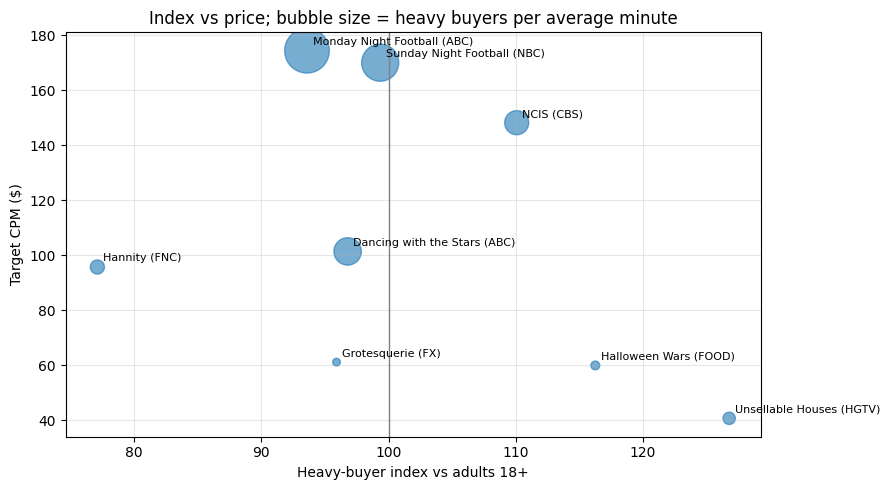

In [7]:
best = {"index": program_table.loc[program_table["index"].idxmax(), "program"],
        "volume": program_table.loc[program_table["target_viewers"].idxmax(), "program"],
        "cpm": program_table.loc[program_table["target_cpm"].idxmin(), "program"]}
print("Highest index (program):", best["index"])
print("Most target viewers (program):", best["volume"])
print("Lowest target CPM (program):", best["cpm"])

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(program_table["index"], program_table["target_cpm"], s=program_table["target_viewers_k"] / 4, alpha=0.6)
for _, row in program_table.iterrows():
    ax.annotate(row["program"], (row["index"], row["target_cpm"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.axvline(100, color="grey", linewidth=1)
ax.set_xlabel("Heavy-buyer index vs adults 18+")
ax.set_ylabel("Target CPM ($)")
ax.set_title("Index vs price; bubble size = heavy buyers per average minute")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Answer:

Same program or not: No—two different programs split the three metrics. Unsellable Houses (HGTV) has both the highest index (126.8) and the lowest target CPM ($40.66), while Monday Night Football (ABC) delivers the most target viewers (4.15M vs. 317k), despite a 93.6 index and $174.40 target CPM. Overall, sports and broadcast hits (MNF, SNF, NCIS, Dancing with the Stars) deliver volume, whereas cable networks (HGTV, Food Network, FX) deliver cost efficiency.

What to tell the client: An index measures audience concentration, not scale or cost—as in Lecture 5's shampoo example, high-index shows are usually small. Unsellable Houses averages only 317k heavy buyers per spot (24.9% composition vs. 19.6% in the population). Spending $1M there would require 77 prime-time spots—more inventory than the show airs—and would repeatedly hit the same small group while missing the rest of the 49.6M target. Instead, buy primarily on target CPM and reach/volume, and use the index only as a tie-breaker or guardrail to avoid off-target shows like Hannity (77)—a near-average index (such as NFL at 93–99) can still be a top volume driver.

## Task 2.3 — Kestrel buyers

In [8]:
kestrel_table = program_table[["program", "index", "kestrel_index", "target_panelists", "kestrel_panelists"]].rename(
    columns={"index": "heavy_index", "target_panelists": "heavy_panelists_per_telecast",
             "kestrel_panelists": "kestrel_panelists_per_telecast"})
print("table: program, heavy-buyer index, Kestrel index (and the panelists behind them)")
show(kestrel_table, {"heavy_index": ".1f", "kestrel_index": ".1f",
                     "heavy_panelists_per_telecast": ".1f", "kestrel_panelists_per_telecast": ".1f"})
print()
print("Spread of the index across the 8 programs (std), heavy / Kestrel:",
      f"{kestrel_table['heavy_index'].std():.1f}", "/", f"{kestrel_table['kestrel_index'].std():.1f}")
print("Panel n, heavy buyers / Kestrel buyers:", len(HEAVY), "/", len(KESTREL))

table: program, heavy-buyer index, Kestrel index (and the panelists behind them)
                     program heavy_index kestrel_index heavy_panelists_per_telecast kestrel_panelists_per_telecast
 Sunday Night Football (NBC)        99.3          98.5                        329.0                           75.2
 Monday Night Football (ABC)        93.6          85.9                        292.7                           69.3
Dancing with the Stars (ABC)        96.8          82.7                        122.6                           23.4
                  NCIS (CBS)       110.1          56.5                         86.3                           11.0
               Hannity (FNC)        77.1          42.6                         15.9                            2.1
    Unsellable Houses (HGTV)       126.8          76.9                         25.4                            4.0
       Halloween Wars (FOOD)       116.2          95.2                         13.7                            2.8

Answer:

Why it jumps: The Kestrel index varies widely (42.6 on Hannity to 129.6 on Grotesquerie; SD 26.5 vs. 15.3 for heavy buyers) and clashes with heavy buyers on NCIS (56.5 vs. 110.1) and Grotesquerie (129.6 vs. 95.9). While Kestrel buyers are genuinely younger (55+ indices of 58–68), the main cause is small sample size: there are only 354 Kestrel panelists total, and just 2–4 watch an average cable telecast, so adding or losing a single viewer shifts the index by 25–50 points. Heavy buyers have 1,661 panelists (nearly 5x more).

Which to trust: Trust the heavy-buyer index, especially on the four broadcast programs (86–329 heavy-buyer panelists per telecast vs. 11–25 on cable). Avoid using the Kestrel index for program selection except on NFL games, where ~70 Kestrel panelists watch per telecast and both indices align (86–99).

How to check:

Split-half / bootstrap: Split October telecasts in half (e.g., odd vs. even) or bootstrap panelists—true signal repeats, noise does not.

Demographic benchmark: Compare the observed Kestrel index against the program's expected index based on its age/sex/income mix (from Task 1.2); since purchase attributes were fused purely via demographics, large deviations are sample noise by construction.

Larger samples: Pool multiple months of panel data or link purchases to the larger smart-TV footprint before relying on a 354-person segment.

## Task 3.1 — Weights

In [9]:
# Smart-TV rules from Lab 3: Eastern time, broadcast day 06:00-05:59, 1-minute edit rule,
# in-tab = at least one session that day, viewing = a live session on the network overlapping
# the telecast by at least a minute, match = the IP belongs to exactly one household.
# (6.4M rows: keep only the columns needed and build the day label once per unique day.)
acr = acr_sessions[["tv_id", "session_type", "network_code"]].copy()
acr["start_et"] = acr_sessions["start_utc"].dt.tz_convert("America/New_York").dt.tz_localize(None)
acr["end_et"] = acr_sessions["end_utc"].dt.tz_convert("America/New_York").dt.tz_localize(None)
day_codes, day_values = pd.factorize((acr["start_et"] - pd.Timedelta(hours=6)).dt.floor("D"))
acr["broadcast_day"] = pd.Categorical.from_codes(day_codes, categories=day_values.strftime("%Y-%m-%d"))
sessions_clean = acr[(acr["end_et"] - acr["start_et"]) >= pd.Timedelta(minutes=1)]
live_sessions = sessions_clean[sessions_clean["session_type"] == "live"]

tv_ips = acr_sessions[["tv_id", "hashed_ip"]].drop_duplicates(subset=["tv_id"])
households_per_ip = hh_attributes.groupby("hashed_ip")["household_id"].nunique()
matched_tvs = tv_ips[tv_ips["hashed_ip"].map(households_per_ip) == 1].merge(
    hh_attributes[["hashed_ip", "income_band", "head_age_band"]], on="hashed_ip")
matched_tvs["head_age"] = np.where(matched_tvs["head_age_band"] == "65+", "65+", "Under 65")

# In-tab matched TVs per day and cell, and the cell weight for that day.
intab = sessions_clean[["tv_id", "broadcast_day"]].drop_duplicates().astype({"broadcast_day": str}).merge(
    matched_tvs[["tv_id", "head_age", "income_band"]], on="tv_id")
cell_counts = intab.groupby(["broadcast_day", "head_age", "income_band"]).size().rename("intab_tvs").reset_index()
cell_counts = cell_counts.merge(universe, on=["head_age", "income_band"])
cell_counts["weight"] = cell_counts["tv_households"] / cell_counts["intab_tvs"]
intab = intab.merge(cell_counts[["broadcast_day", "head_age", "income_band", "weight"]],
                    on=["broadcast_day", "head_age", "income_band"])

weight_sums = intab.groupby("broadcast_day")["weight"].sum()
print("TVs matched to one household:", len(matched_tvs))
print("Weights sum per day (M):", f"{weight_sums.min() / 1e6:.1f}", "to", f"{weight_sums.max() / 1e6:.1f}",
      f"over {len(weight_sums)} days (universe {universe['tv_households'].sum() / 1e6:.1f})")
print("Cells empty on any day:", int((cell_counts.groupby("broadcast_day").size() < len(universe)).sum()))
print()

ref_telecasts = reference_ratings.merge(programs, on="telecast_id")
rows = []
for _, t in ref_telecasts.iterrows():
    day_tvs = intab[intab["broadcast_day"] == t["broadcast_date"]]
    on_net = live_sessions[(live_sessions["network_code"] == t["network_code"]) &
                           (live_sessions["start_et"] < t["end_ts"]) & (live_sessions["end_et"] > t["start_ts"])]
    overlap = (on_net["end_et"].clip(upper=t["end_ts"]) - on_net["start_et"].clip(lower=t["start_ts"])).dt.total_seconds() / 60
    watched = day_tvs["tv_id"].isin(set(on_net.loc[overlap >= 1.0, "tv_id"]))
    rows.append({"telecast": label(t["program_name"], t["network_code"]), "date": t["broadcast_date"],
                 "unweighted": watched.mean() * 100,
                 "weighted": day_tvs.loc[watched, "weight"].sum() / day_tvs["weight"].sum() * 100,
                 "reference": t["hh_rating"]})
weighting = pd.DataFrame(rows)
weighting["moved"] = weighting["weighted"] - weighting["unweighted"]
print("table: telecast, unweighted, weighted, reference (household ratings of matched TVs)")
show(weighting, {"unweighted": ".2f", "weighted": ".2f", "reference": ".2f", "moved": "+.2f"})
gap_unweighted = (weighting["reference"] - weighting["unweighted"]).abs().mean()
gap_weighted = (weighting["reference"] - weighting["weighted"]).abs().mean()
print()
print("Mean gap unweighted (points):", f"{gap_unweighted:.2f}")
print("Mean gap weighted (points):", f"{gap_weighted:.2f}")
print("Share of gap closed:", f"{(gap_unweighted - gap_weighted) / gap_unweighted:.3f}")

# Footprint vs universe by cell (why the weights move what they move).
cell_mix = cell_counts.groupby(["head_age", "income_band"]).agg(intab_tvs=("intab_tvs", "mean"),
                                                                 tv_households=("tv_households", "first"),
                                                                 weight=("weight", "mean")).reset_index()
cell_mix["footprint_share"] = cell_mix["intab_tvs"] / cell_mix["intab_tvs"].sum()
cell_mix["universe_share"] = cell_mix["tv_households"] / cell_mix["tv_households"].sum()
cell_mix["index"] = cell_mix["footprint_share"] / cell_mix["universe_share"] * 100
print()
print("table: footprint vs universe by cell (mean over days)")
show(cell_mix[["head_age", "income_band", "intab_tvs", "footprint_share", "universe_share", "index", "weight"]],
     {"intab_tvs": ".0f", "footprint_share": ".3f", "universe_share": ".3f", "index": ".1f", "weight": ".0f"})

TVs matched to one household: 19607
Weights sum per day (M): 125.8 to 125.8 over 14 days (universe 125.8)
Cells empty on any day: 0

table: telecast, unweighted, weighted, reference (household ratings of matched TVs)
                                    telecast       date unweighted weighted reference moved
                        MLB Postseason (FOX) 2024-10-25      17.03    17.76     25.86 +0.72
                          NFL Football (NBC) 2024-10-27      22.62    23.75     33.14 +1.13
                                  NCIS (CBS) 2024-10-14       5.50     5.80     10.56 +0.29
                               Hannity (FNC) 2024-10-16       1.04     1.35      2.30 +0.31
                    Unsellable Houses (HGTV) 2024-10-16       2.12     2.08      3.69 -0.04
        Halloween Baking Championship (FOOD) 2024-10-14       0.95     0.90      1.63 -0.05
                           Grotesquerie (FX) 2024-10-16       2.17     2.11      3.53 -0.06
The Real Housewives of New York City (BRAVO) 20

## Task 3.2 — What weighting cannot fix
**Answer:** what moved and why; what is left; why income barely matters here.

**What moved, which way, and why.** Weighting raised the four big-network telecasts and lowered the four cable ones. Sunday Night Football +1.13 points, the MLB postseason +0.72, Hannity +0.31 and NCIS +0.29 went up. Unsellable Houses, the Food Network bake-off, Grotesquerie and Real Housewives each went down by 0.04-0.07. The cell table shows why. The footprint is short of homes with a head 65+, especially low-income ones: 65+ under \$25k sits at index 46 and 65+ \$25-50k at 54, so each of those TVs gets a weight of 12-15k against about 5-6k for under-65 homes earning \$75k+ (index 117-138). Weighting therefore hands the older homes back their votes, and older homes are the ones watching broadcast networks, Fox News and live sport. The younger, more affluent homes that over-index on HGTV, FX and Bravo count for less. The direction is exactly the Lab 3 profile, and Hannity, the most under-stated telecast in Lab 3, moves the most in relative terms (+30%).

**Most of the gap is still there.** The mean gap only falls from 3.73 to 3.44 points (7.5% closed), and every weighted rating is still 52-72% of the reference. Weighting only redistributes the in-tab TVs across cells; it cannot create viewing the footprint never saw. What it cannot fix: (1) **one set per home**: the reference is a household rating across all of a home's ~2.6 sets, the footprint sees one; (2) **unrecognised viewing**: only `live` sessions carry a network, so a home watching NBC through an app or a vMVPD counts as in-tab but not viewing, and in Lab 3 39.6% of hours were `unknown`; (3) **the match**: only 19,607 of ~30,000 TVs resolve to exactly one household, and the ones lost to shared or unmatched IPs are not random; (4) **selection inside the cells**: weighting assumes that opted-in homes in a cell view like all homes in that cell (Lecture 4: weighting fixes the *observed* variables only). A 65+ home that bought a connected smart TV and left ACR on is not a typical 65+ home, and no weight can see that.

**Why weighting by income barely moves these ratings.** Weighting changes a rating only if the weighting variable is correlated with viewing the program. The footprint is skewed by income, but in this population viewing of these programs depends mainly on age, not on income *within* an age group. Moving weight from \$150k+ to under-\$50k homes of the same age therefore swaps viewers for viewers who watch the same way. The only cells that move anything are the 65+ cells, and those correct age, not income. The universe here only has two age groups, so even the age correction is coarse: 18-34 and 50-64 heads are treated as one cell.

## Task 4.1 — October predicts October

Telecasts forecast (n): 101
Telecasts scored, P2+ / heavy buyers (actual > 0): 101 / 101
MAPE, P2+ (%): 35.8
MAPE, heavy buyers (%): 38.6
Biggest miss, P2+ (program, date): Krapopolis (FOX) 2024-10-27
WAPE, P2+ / heavy buyers (%): 22.8 / 24.6
Median APE, P2+ / heavy buyers (%): 19.7 / 21.8


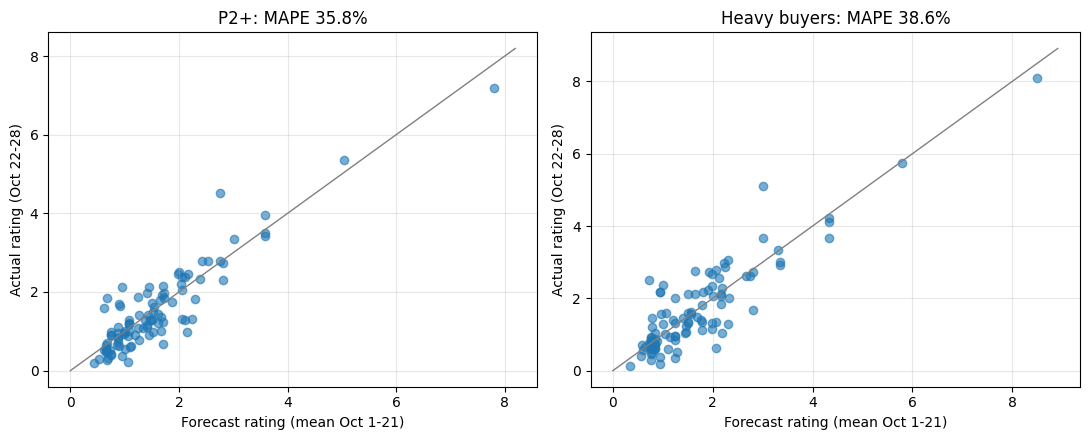

In [10]:
HISTORY = [f"2024-10-{d:02d}" for d in range(1, 22)]
FORECAST_WEEK = [f"2024-10-{d:02d}" for d in range(22, 29)]
FIVE_NETWORKS = ["CBS", "NBC", "ABC", "FOX", "FNC"]

prime5 = programs[(programs["daypart"] == "Prime") & programs["network_code"].isin(FIVE_NETWORKS) &
                  programs["broadcast_date"].isin(HISTORY + FORECAST_WEEK)].copy()
prime5["key"] = list(zip(prime5["program_name"], prime5["network_code"]))
minutes5 = telecast_minutes(prime5)
prime5 = prime5.join(ratings_for(prime5, minutes5, P2_PLUS)["rating"].rename("p2"), on="telecast_id")
prime5 = prime5.join(ratings_for(prime5, minutes5, HEAVY)["rating"].rename("heavy"), on="telecast_id")

history = prime5[prime5["broadcast_date"].isin(HISTORY)].groupby("key")[["p2", "heavy"]].mean()
forecast = prime5[prime5["broadcast_date"].isin(FORECAST_WEEK) & prime5["key"].isin(history.index)].copy()
forecast["forecast_p2"] = forecast["key"].map(history["p2"])
forecast["forecast_heavy"] = forecast["key"].map(history["heavy"])
forecast["program"] = [label(n, c) for n, c in forecast["key"]]
for aud in ["p2", "heavy"]:
    actual = forecast[aud].where(forecast[aud] > 0)  # skip telecasts whose actual rating is 0
    forecast[f"ape_{aud}"] = (actual - forecast[f"forecast_{aud}"]).abs() / actual * 100
mape_p2 = forecast["ape_p2"].mean()
mape_heavy = forecast["ape_heavy"].mean()
worst = forecast.loc[forecast["ape_p2"].idxmax()]

print("Telecasts forecast (n):", len(forecast))
print("Telecasts scored, P2+ / heavy buyers (actual > 0):", int(forecast["ape_p2"].notna().sum()), "/",
      int(forecast["ape_heavy"].notna().sum()))
print("MAPE, P2+ (%):", f"{mape_p2:.1f}")
print("MAPE, heavy buyers (%):", f"{mape_heavy:.1f}")
print("Biggest miss, P2+ (program, date):", worst["program"], worst["broadcast_date"])
print("WAPE, P2+ / heavy buyers (%):",
      f"{(forecast['p2'] - forecast['forecast_p2']).abs().sum() / forecast['p2'].sum() * 100:.1f}", "/",
      f"{(forecast['heavy'] - forecast['forecast_heavy']).abs().sum() / forecast['heavy'].sum() * 100:.1f}")
print("Median APE, P2+ / heavy buyers (%):", f"{forecast['ape_p2'].median():.1f}", "/", f"{forecast['ape_heavy'].median():.1f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, aud, title in [(ax[0], "p2", "P2+"), (ax[1], "heavy", "Heavy buyers")]:
    a.scatter(forecast[f"forecast_{aud}"], forecast[aud], alpha=0.6)
    lim = max(forecast[f"forecast_{aud}"].max(), forecast[aud].max()) * 1.05
    a.plot([0, lim], [0, lim], color="grey", linewidth=1)
    a.set_xlabel("Forecast rating (mean Oct 1-21)")
    a.set_ylabel("Actual rating (Oct 22-28)")
    a.set_title(f"{title}: MAPE {forecast[f'ape_{aud}'].mean():.1f}%")
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Task 4.2 — Why it missed

In [11]:
misses = forecast.sort_values("ape_p2", ascending=False).head(5)
print("table: the five biggest misses, P2+ (program, date, forecast, actual)")
show(misses.assign(start=misses["start_ts"].dt.strftime("%H:%M"), end=misses["end_ts"].dt.strftime("%H:%M"))[
    ["program", "broadcast_date", "start", "end", "forecast_p2", "p2", "ape_p2", "forecast_heavy", "heavy"]].rename(
    columns={"broadcast_date": "date", "p2": "actual_p2", "ape_p2": "error_%", "heavy": "actual_heavy"}),
    {"forecast_p2": ".2f", "actual_p2": ".2f", "error_%": ".1f", "forecast_heavy": ".2f", "actual_heavy": ".2f"})

print()
for _, m in misses.iterrows():
    net, day = m["network_code"], m["broadcast_date"]
    print(f"{m['program']} on {day} — prime schedule that night:")
    night = programs[(programs["network_code"] == net) & (programs["broadcast_date"] == day) &
                     (programs["start_ts"].dt.hour >= 19)].sort_values("start_ts")
    for _, p in night.iterrows():
        episode = "" if pd.isna(p["episode_name"]) else f" — {p['episode_name']}"
        flags = " [live]" if p["is_live"] else ""
        flags += " [repeat]" if p["is_repeat"] else ""
        print(f"   {p['start_ts']:%H:%M}-{p['end_ts']:%H:%M}  {p['program_name']}{episode}{flags}")
    hist = prime5[(prime5["key"] == m["key"]) & prime5["broadcast_date"].isin(HISTORY)]
    print("   history telecasts:", ", ".join(f"{d} {s:%H:%M} ({r:.2f})" for d, s, r in
                                            zip(hist["broadcast_date"], hist["start_ts"], hist["p2"])))

# Error vs the number of in-target panelists behind each rating (Lecture 6: error vs sample size).
forecast = forecast.join(ratings_for(forecast, minutes5, HEAVY)["panelists"].rename("heavy_panelists"), on="telecast_id")
forecast = forecast.join(ratings_for(forecast, minutes5, P2_PLUS)["panelists"].rename("p2_panelists"), on="telecast_id")
print()
print("Median panelists viewing a forecast-week telecast, P2+ / heavy buyers:",
      f"{forecast['p2_panelists'].median():.0f}", "/", f"{forecast['heavy_panelists'].median():.0f}")
print("Heavy-buyer telecasts with an actual of 0 (skipped):", int((forecast["heavy"] == 0).sum()))

table: the five biggest misses, P2+ (program, date, forecast, actual)
                   program       date start   end forecast_p2 actual_p2 error_% forecast_heavy actual_heavy
          Krapopolis (FOX) 2024-10-27 21:30 22:00        1.06      0.22   387.8           1.25         0.35
Universal Basic Guys (FOX) 2024-10-27 20:30 21:00        0.68      0.26   162.2           0.95         0.19
        Fire Country (CBS) 2024-10-27 22:44 23:00        1.70      0.67   154.8           2.07         0.61
             Accused (FOX) 2024-10-22 21:00 22:00        0.95      0.37   154.6           0.94         0.38
  What Would You Do? (ABC) 2024-10-23 22:00 23:00        0.44      0.18   138.1           0.34         0.11

Krapopolis (FOX) on 2024-10-27 — prime schedule that night:
   19:15-20:00  Local / Syndicated Programming
   20:00-20:30  The Simpsons — Shoddy Heat
   20:30-21:00  Universal Basic Guys — Fight or Flight
   21:00-21:30  Bob's Burgers — For Whom the Doll Toes
   21:30-22:00  Krapo

Answer:

What happened on the five biggest misses: All five are small shows that were over-forecast due to schedule changes rather than shifts in viewer taste:

Krapopolis (FOX), 2024-10-27 (1.06 vs. 0.22): History averaged high-rated Wednesday repeats after The Floor (1.76, 1.93) with low-rated Sunday originals (0.26, 0.30).

Universal Basic Guys (FOX), 2024-10-27 (0.68 vs. 0.26): History was inflated by a post-national NFL lead-in on Oct 20; on Oct 27 it aired later at 20:30 after shorter regional games.

Fire Country (CBS), 2024-10-27 (1.70 vs. 0.67): An NFL overrun pushed 60 Minutes, splitting the repeat into short fragments; the 16-minute late stub caused the miss.

Accused (FOX), 2024-10-22 (0.95 vs. 0.37): History included Oct 1 (1.87), when FOX was the only major network not airing the VP debate, followed by a steady drop to 0.38.

What Would You Do? (ABC), 2024-10-23 (0.44 vs. 0.18): History included a Monday airing with a strong Dancing with the Stars lead-in; on a 0.18 base, a 0.26-point miss equals 138% error (which is why MAPE is 35.8% vs. 22.8% WAPE).

Why the heavy-buyer forecast is worse (MAPE 38.6% vs. 35.8%; WAPE 24.6% vs. 22.8%): Heavy buyers have a much smaller sample (1,661 panelists vs. ~10,000 for P2+, and a median of 46 viewers per telecast vs. 241). Because sampling noise scales as 1/sqrt(n), both the historical baseline and actual ratings carry much higher relative error on top of the schedule shifts.

Two improvements for a better forecast:

Schedule-aware features: Model by day, time slot, lead-in/lead-out, repeat vs. original status, segment length, and special events (live sports overruns, debates, elections) rather than a simple program average.

Recency weighting & stabilized target index: Weight recent weeks more heavily (e.g., last week matched Accused at 0.37) and forecast target ratings as
P2+ forecast
×
pooled/shrunk target index
P2+ forecast×pooled/shrunk target index to separate stable audience levels from noisy target samples.

## Task 5.1 — The plan

In [12]:
BUDGET = 1_000_000
# What one November week can hold: October prime telecasts per week, at most 2 :30s per telecast.
# Halloween Wars and Grotesquerie are left out: both are October-only and off the air in November.
weekly = (telecasts_8.groupby("program").size() / (31 / 7)).round().clip(lower=1).astype(int)
print("table: prime telecasts per week (October) and the most :30s a week can hold")
print((weekly.to_frame("telecasts_per_week").assign(max_spots=weekly * 2)).to_string())
print()
PLAN_SPOTS = {"Unsellable Houses (HGTV)": 6,      # 3 telecasts x 2: lowest target CPM, highest index
              "Dancing with the Stars (ABC)": 4,  # 2 telecasts x 2: volume at a near-average CPM
              "Hannity (FNC)": 7}                 # 5 telecasts, 1-2 each: fills the rest below $100 CPM
assert all(PLAN_SPOTS[p] <= 2 * weekly[p] for p in PLAN_SPOTS)
plan = program_table.set_index("program").loc[list(PLAN_SPOTS), ["cost_30s", "target_viewers", "adults_viewers", "target_cpm", "index", "composition"]]
plan["spots"] = pd.Series(PLAN_SPOTS)
plan["cost"] = plan["spots"] * plan["cost_30s"]
plan["target_impressions_m"] = plan["spots"] * plan["target_viewers"] / 1e6
plan["adult_impressions_m"] = plan["spots"] * plan["adults_viewers"] / 1e6
print("table: program, spots, cost, target impressions")
show(plan.reset_index()[["program", "spots", "cost_30s", "cost", "target_impressions_m", "target_cpm", "index"]],
     {"cost_30s": ".0f", "cost": ".0f", "target_impressions_m": ".1f", "target_cpm": ".2f", "index": ".1f"})
plan_cost = plan["cost"].sum()
plan_target = plan["target_impressions_m"].sum()
assert plan_cost <= BUDGET
print("Plan cost ($):", f"{plan_cost:.0f}")
print("Plan target impressions (M):", f"{plan_target:.1f}")
print("Plan target CPM ($):", f"{plan_cost / plan_target / 1e3:.2f}")
print("Share of impressions on heavy buyers:", f"{plan_target / plan['adult_impressions_m'].sum():.3f}")
print("Target GRPs:", f"{plan_target * 1e6 / sizes['Heavy buyers (3+)'] * 100:.1f}")
plan_errors = forecast[forecast["program"].isin(PLAN_SPOTS)].groupby("program")[["ape_p2", "ape_heavy"]].mean()
print("Task 4 error on the plan's programs (mean APE %, forecast week):")
print(plan_errors.map(lambda x: f"{x:.1f}").to_string())
print("Delivery range at heavy-buyer MAPE (M):", f"{plan_target * (1 - mape_heavy / 100):.1f}", "to",
      f"{plan_target * (1 + mape_heavy / 100):.1f}")

table: prime telecasts per week (October) and the most :30s a week can hold
                              telecasts_per_week  max_spots
program                                                    
Dancing with the Stars (ABC)                   2          4
Grotesquerie (FX)                              6         12
Halloween Wars (FOOD)                          2          4
Hannity (FNC)                                  5         10
Monday Night Football (ABC)                    1          2
NCIS (CBS)                                     1          2
Sunday Night Football (NBC)                    1          2
Unsellable Houses (HGTV)                       3          6

table: program, spots, cost, target impressions
                     program  spots cost_30s   cost target_impressions_m target_cpm index
    Unsellable Houses (HGTV)      6    12900  77400                  1.9      40.66 126.8
Dancing with the Stars (ABC)      4   158600 634400                  6.3     101.39  96.8
     

Answer: I recommend spending $991,100 on 17 :30 spots to deliver 11.1M heavy-buyer impressions (22.3 target GRPs) at an $89 target CPM: 6 spots in Unsellable Houses (HGTV) (lowest target CPM at $41 and highest index at 126.8), 4 in Dancing with the Stars (ABC) for scale (1.56M target viewers per spot at $101 CPM), and 7 in Hannity (Fox News) at $96 CPM. I excluded the NFL because its $170–$174 target CPM is nearly double and a single Monday Night Football spot takes 72% of the budget, while Halloween Wars and Grotesquerie are October-only shows off the air in November. Delivery carries meaningful uncertainty given Task 4's 38.6% MAPE (24.6% WAPE)—and 18.5%–29.8% error on Hannity and Dancing with the Stars—putting realistic delivery between 6.8M and 15.4M impressions. To protect the budget, I would negotiate an audience guarantee with make-goods and avoid airing during Election Week (November 5), when news spikes and schedule changes break October baselines. On efficiency, the plan's blended composition is 18.5%, meaning about $0.81 of every dollar (~$808k) reaches non-heavy buyers—an unavoidable trade-off on linear TV where no show exceeds ~25% heavy-buyer composition. After the flight, I would run a post-buy audit comparing actual heavy-buyer impressions, reach, and frequency against the 11.1M guarantee. Finally, I would measure business lift by comparing Kestrel sales or site visits between exposed and unexposed homes in the smart-TV footprint linked to purchase data.